# Dataset v1 annotation preparation

## 1. Imports and paths

In [ ]:
### All annotations done using CVAT locally hosted on Docker. 

In [1]:
from collections import Counter
from pathlib import Path, PurePosixPath
from hashlib import sha256
from zipfile import ZipFile
from xml.etree import ElementTree
import json
import math
import shutil

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
from IPython.display import display
from PIL import Image

In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

dataset_dir = project_root / "data" / "dataset_v1"
exports_dir = dataset_dir / "exports"
yolo_dir = dataset_dir / "yolo_dataset"

expected_counts = {"train": 160, "val": 20, "test": 20}
export_subsets = {"val": "Validation", "test": "Test"}
class_name = "license_plate"
seed = 42

manifest = pd.read_csv(dataset_dir / "dataset_manifest.csv")
display(manifest.head())
display(pd.crosstab(manifest["split"], manifest["sampling_category"]))

,image_id,split,sampling_category,source_path,vehicle_count,max_vehicle_area,max_vehicle_width,max_vehicle_height,timeofday,weather,scene,stats_source,reviewed_at_utc
0,e83778ae-3e7047ff.jpg,test,challenging,data/raw/bdd100k/test/e83778ae-3e7047ff.jpg,7,168603.281250,1265.909180,133.187500,NaN,NaN,NaN,coco_yolo11n_cpu,2026-11-25T08:14:02.359886+00:00
1,ee8032be-6ec5c25e.jpg,test,challenging,data/raw/bdd100k/test/ee8032be-6ec5c25e.jpg,4,223669.671875,481.665100,464.367615,NaN,NaN,NaN,coco_yolo11n_cpu,2026-11-25T08:15:20.709417+00:00
2,cf9eddc7-49e3c6fa.jpg,test,clear,data/raw/bdd100k/test/cf9eddc7-49e3c6fa.jpg,9,185656.328125,1269.399414,146.255249,NaN,NaN,NaN,coco_yolo11n_cpu,2026-11-25T08:17:07.199599+00:00
3,d27a2be8-7e1c1b78.jpg,test,clear,data/raw/bdd100k/test/d27a2be8-7e1c1b78.jpg,10,249288.984375,1272.688721,195.875854,NaN,NaN,NaN,coco_yolo11n_cpu,2026-11-25T08:16:43.806820+00:00
4,d4c3130d-ede98fc6.jpg,test,clear,data/raw/bdd100k/test/d4c3130d-ede98fc6.jpg,3,132519.968750,486.860901,272.192657,NaN,NaN,NaN,coco_yolo11n_cpu,2026-11-25T08:17:31.871950+00:00


sampling_category,challenging,clear,negative
split,,,
test,2,16,2
train,16,128,16
val,2,16,2


## 2. Inspect the CVAT exports

In [3]:
for split in expected_counts:
    with ZipFile(exports_dir / f"{split}.zip") as archive:
        members = archive.namelist()
        print(f"{split}.zip ({len(members)} entries)")
        print(*members[:6], sep="\n")
        if "annotations.xml" in members:
            root = ElementTree.fromstring(archive.read("annotations.xml"))
            example = next(image for image in root.findall("image") if image.find("box") is not None)
            print(ElementTree.tostring(example, encoding="unicode").strip())
        else:
            print(archive.read("data.yaml").decode().strip())
            sample = next(name for name in members if name.startswith("labels/") and name.endswith(".txt"))
            print(sample)
            print(archive.read(sample).decode().strip())
        print()

train.zip (1 entries)
annotations.xml
<image id="1" name="02205e0f-20f9ad20.jpg" width="1280" height="720">
    <box label="license_plate" source="manual" occluded="0" xtl="414.47" ytl="515.32" xbr="514.07" ybr="568.22" z_order="0">
    </box>
  </image>

val.zip (17 entries)
Validation.txt
data.yaml
labels/Validation/bb6f381e-02e9cc6b.txt
labels/Validation/b255cd6c-e5f99451.txt
labels/Validation/c75e23fe-086d84a6.txt
labels/Validation/c2e3fe05-fa312f4d.txt
Validation: Validation.txt
names:
  0: license_plate
path: .
labels/Validation/bb6f381e-02e9cc6b.txt
0 0.649777 0.565750 0.048805 0.046472

test.zip (15 entries)
data.yaml
Test.txt
labels/Test/e548fb26-4a506fca.txt
labels/Test/eb17095a-794bd4e5.txt
labels/Test/f6f08dfe-32d3f6a9.txt
labels/Test/e229a840-1b7f07fd.txt
Test: Test.txt
names:
  0: license_plate
path: .
labels/Test/e548fb26-4a506fca.txt
0 0.441406 0.584493 0.063797 0.064819



## 3. Prepare image and label records

The train export uses CVAT XML with pixel corners. Validation and test use normalized YOLO labels. The manifest defines split membership and which images are confirmed negatives.

In [4]:
duplicate_ids = manifest["image_id"].str.casefold().duplicated(keep=False)
display(manifest.loc[duplicate_ids, ["split", "image_id"]])
assert not duplicate_ids.any(), "Duplicate image IDs in the manifest"
assert manifest["split"].value_counts().to_dict() == expected_counts
assert manifest["sampling_category"].isin(["clear", "challenging", "negative"]).all()

manifest["image_path"] = [
    dataset_dir / row.split / row.image_id for row in manifest.itertuples(index=False)
]
missing_images = manifest.loc[~manifest["image_path"].map(Path.is_file)]
display(missing_images[["split", "image_id", "image_path"]])
assert missing_images.empty, "Selected images are missing"

image_sizes = []
image_hashes = []
for path in manifest["image_path"]:
    with Image.open(path) as image:
        image_sizes.append(image.size)
    image_hashes.append(sha256(path.read_bytes()).hexdigest())

manifest[["image_width", "image_height"]] = pd.DataFrame(image_sizes, index=manifest.index)
manifest["image_hash"] = image_hashes
duplicates = manifest["image_hash"].duplicated(keep=False)
display(manifest.loc[duplicates, ["split", "image_id"]])
assert not duplicates.any(), "Duplicate image contents"
display(manifest.groupby(["image_width", "image_height"]).size().rename("images"))

,split,image_id


,split,image_id,image_path


,split,image_id


image_width  image_height
1280         720             200
Name: images, dtype: int64

In [5]:
# Use the original filename stem to match labels to images within each split.
manifest["stem"] = manifest["image_id"].map(lambda name: Path(name).stem)
assert not manifest.duplicated(["split", "stem"]).any()

image_lookup = manifest.set_index(["split", "image_id"])
export_images = {}
label_lines = {}
issues = []

with ZipFile(exports_dir / "train.zip") as archive:
    root = ElementTree.fromstring(archive.read("annotations.xml"))

train_images = root.findall("image")
export_images["train"] = [PurePosixPath(image.attrib["name"]).name for image in train_images]

for image, image_id in zip(train_images, export_images["train"]):
    width, height = float(image.attrib["width"]), float(image.attrib["height"])
    key = ("train", image_id)
    if key in image_lookup.index:
        expected_size = tuple(image_lookup.loc[key, ["image_width", "image_height"]])
        if (width, height) != expected_size:
            issues.append(("train", image_id, "XML image dimensions differ from the selected image"))

    lines = []
    for box in image.findall("box"):
        x1, y1, x2, y2 = (float(box.attrib[name]) for name in ("xtl", "ytl", "xbr", "ybr"))
        class_id = "0" if box.attrib["label"] == class_name else "invalid"
        if class_id == "invalid":
            issues.append(("train", image_id, f"Unexpected XML label {box.attrib['label']!r}"))
        values = ((x1 + x2) / (2 * width), (y1 + y2) / (2 * height),
                  (x2 - x1) / width, (y2 - y1) / height)
        lines.append(" ".join([class_id, *(f"{value:.10f}" for value in values)]))

    label_lines[("train", Path(image_id).stem)] = lines

print(f"Train XML: {len(train_images)} images, {sum(map(len, label_lines.values()))} boxes")

Train XML: 160 images, 151 boxes


In [6]:
for split, subset in export_subsets.items():
    with ZipFile(exports_dir / f"{split}.zip") as archive:
        image_list = archive.read(f"{subset}.txt").decode().splitlines()
        export_images[split] = [PurePosixPath(line.strip()).name for line in image_list if line.strip()]

        for entry in archive.infolist():
            path = PurePosixPath(entry.filename)
            if path.parts[0] != "labels" or path.suffix != ".txt":
                continue
            key = (split, path.stem)
            if key in label_lines:
                issues.append((split, entry.filename, "Duplicate label file for image stem"))
            label_lines[key] = archive.read(entry).decode().splitlines()

    print(f"{split}: {len(export_images[split])} listed images")

val: 20 listed images
test: 20 listed images


## 4. Validate annotations

For this run, skip positive images with empty or missing labels. The notebook lists the skipped images and writes empty label files for confirmed negatives. Other annotation issues still block export.

In [7]:
membership_issues = issues.copy()
for split, names in export_images.items():
    expected_names = set(manifest.loc[manifest["split"] == split, "image_id"])
    for name, count in Counter(names).items():
        if count > 1:
            membership_issues.append((split, name, "Duplicate image in export"))
    for name in sorted(set(names) - expected_names):
        membership_issues.append((split, name, "Export image is outside the manifest split"))
    for name in sorted(expected_names - set(names)):
        membership_issues.append((split, name, "Manifest image missing from export image list"))

expected_keys = set(zip(manifest["split"], manifest["stem"]))
for split, stem in sorted(label_lines.keys() - expected_keys):
    membership_issues.append((split, stem + ".txt", "Orphan label file"))

In [8]:
# YOLO labels store center x, center y, width and height as fractions.
box_columns = ["split", "image_id", "line_number", "cx", "cy", "width_norm", "height_norm"]
validation_issues = membership_issues.copy()
box_records = []
label_counts = {}
edge_tolerance = 0.000001  # Allows rounding at image edges.

for row in manifest.itertuples(index=False):
    key = (row.split, row.stem)
    lines = label_lines.get(key, [])
    label_counts[key] = sum(bool(line.strip()) for line in lines)

    if row.sampling_category == "negative" and label_counts[key]:
        validation_issues.append((row.split, row.image_id, "Negative image has annotations"))

    for line_number, line in enumerate(lines, start=1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != 5:
            validation_issues.append((row.split, row.image_id, f"Line {line_number}: expected 5 fields"))
            continue

        class_id, *coordinates = fields
        if class_id != "0":
            validation_issues.append((row.split, row.image_id, f"Line {line_number}: invalid class ID {class_id!r}"))
            continue

        try:
            cx, cy, width, height = map(float, coordinates)
        except ValueError:
            validation_issues.append((row.split, row.image_id, f"Line {line_number}: nonnumeric box"))
            continue

        valid_values = all(math.isfinite(value) and 0 <= value <= 1
                           for value in (cx, cy, width, height))
        within_edges = (
            min(cx - width / 2, cy - height / 2) >= -edge_tolerance
            and max(cx + width / 2, cy + height / 2) <= 1 + edge_tolerance
        )
        if not valid_values or width <= 0 or height <= 0 or not within_edges:
            validation_issues.append((row.split, row.image_id, f"Line {line_number}: invalid box {line.strip()}"))
            continue

        box_records.append((row.split, row.image_id, line_number, cx, cy, width, height))

problems = pd.DataFrame(validation_issues, columns=["split", "record", "issue"])
display(problems)
print(f"{len(problems)} blocking annotation issues")

,split,record,issue


0 blocking annotation issues


In [9]:
plate_counts = pd.Series([
    label_counts[(row.split, row.stem)] for row in manifest.itertuples(index=False)
], index=manifest.index)
skip_image = manifest["sampling_category"].ne("negative") & plate_counts.eq(0)
yolo_manifest = manifest.loc[~skip_image].copy()

print(f"Skipping {skip_image.sum()} positive images with no annotations")
display(manifest.loc[skip_image, ["split", "image_id", "sampling_category"]])
display(yolo_manifest["split"].value_counts().reindex(expected_counts).rename("images to export"))

Skipping 10 positive images with no annotations


,split,image_id,sampling_category
4,test,d4c3130d-ede98fc6.jpg,clear
12,test,eab6b82e-8c0212b2.jpg,clear
14,test,ebe30212-a17583f1.jpg,clear
16,test,f70e1d66-3e63b544.jpg,clear
17,test,f79756ee-ddc10cc9.jpg,clear
25,train,20ff37cb-73e58926.jpg,challenging
29,train,62051da6-86e414ee.jpg,challenging
185,val,b2e54795-d8c2ba6d.jpg,clear
186,val,b35c1016-5a7c77ee.jpg,clear
188,val,b4253085-85838593.jpg,clear


split
train    158
val       17
test      15
Name: images to export, dtype: int64

### Write the YOLO dataset

In [10]:
assert problems.empty, "Resolve the annotation issues above and rerun from the export-loading cells."

# Flag stale files before copying so reruns preserve exact split membership.
generated_files = {}
for split in expected_counts:
    names = yolo_manifest.loc[yolo_manifest["split"] == split, "image_id"]
    generated_files[yolo_dir / "images" / split] = set(names)
    generated_files[yolo_dir / "labels" / split] = {f"{Path(name).stem}.txt" for name in names}

unexpected = [
    path for folder, names in generated_files.items() if folder.is_dir()
    for path in folder.iterdir() if path.name not in names
]
assert not unexpected, f"Move unexpected files out of the YOLO split folders: {unexpected}"

for folder in generated_files:
    folder.mkdir(parents=True, exist_ok=True)

In [11]:
for row in yolo_manifest.itertuples(index=False):
    destination = yolo_dir / "images" / row.split / row.image_id
    shutil.copy2(row.image_path, destination)

    label_path = yolo_dir / "labels" / row.split / f"{row.stem}.txt"
    lines = [line.strip() for line in label_lines.get((row.split, row.stem), []) if line.strip()]
    label_path.write_text("".join(f"{line}\n" for line in lines), encoding="utf-8")

data_yaml = yolo_dir / "data.yaml"
dataset_config = {
    "path": yolo_dir.resolve().as_posix(),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
}
yaml_text = "".join(f"{key}: {json.dumps(value)}\n" for key, value in dataset_config.items())
yaml_text += f"names:\n  0: {class_name}\n"
data_yaml.write_text(yaml_text, encoding="utf-8")
print(data_yaml.read_text(encoding="utf-8"))

path: "C:/Users/aarish.tickoo/workspace/traffic-pii-masking/data/dataset_v1/yolo_dataset"
train: "images/train"
val: "images/val"
test: "images/test"
names:
  0: license_plate



## 5. Annotation statistics

In [12]:
annotation_stats = yolo_manifest[["split", "image_id", "sampling_category",
                             "image_width", "image_height"]].copy()
annotation_stats["plate_count"] = plate_counts.loc[yolo_manifest.index]
annotation_stats["positive"] = annotation_stats["plate_count"].gt(0)
annotation_stats["negative"] = annotation_stats["sampling_category"].eq("negative")
display(annotation_stats.head())

summary = annotation_stats.groupby("split").agg(
    images=("image_id", "size"),
    positive_images=("positive", "sum"),
    negative_images=("negative", "sum"),
    plates=("plate_count", "sum"),
)
display(summary.reindex(expected_counts))

,split,image_id,sampling_category,image_width,image_height,plate_count,positive,negative
0,test,e83778ae-3e7047ff.jpg,challenging,1280,720,1,True,False
1,test,ee8032be-6ec5c25e.jpg,challenging,1280,720,1,True,False
2,test,cf9eddc7-49e3c6fa.jpg,clear,1280,720,3,True,False
3,test,d27a2be8-7e1c1b78.jpg,clear,1280,720,2,True,False
5,test,d58cbda2-a112275b.jpg,clear,1280,720,1,True,False


,images,positive_images,negative_images,plates
split,,,,
train,158,142,16,151
val,17,15,2,15
test,15,13,2,16


## 6. Bounding box sizes

For a square input, aspect-ratio-preserving resizing uses a scale of `input_size / max(image_width, image_height)`. Letterbox padding leaves box dimensions unchanged.

In [13]:
boxes = pd.DataFrame(box_records, columns=box_columns).merge(
    annotation_stats[["split", "image_id", "image_width", "image_height"]],
    on=["split", "image_id"],
    validate="many_to_one",
)
boxes["width_px"] = boxes["width_norm"] * boxes["image_width"]
boxes["height_px"] = boxes["height_norm"] * boxes["image_height"]
boxes["area_px2"] = boxes["width_px"] * boxes["height_px"]

long_side = boxes[["image_width", "image_height"]].max(axis=1)
for input_size in [640, 960, 1280]:
    scale = input_size / long_side
    boxes[f"width_at_{input_size}"] = boxes["width_px"] * scale
    boxes[f"height_at_{input_size}"] = boxes["height_px"] * scale

display(boxes.head())

,split,image_id,line_number,cx,cy,width_norm,height_norm,image_width,image_height,width_px,height_px,area_px2,width_at_640,height_at_640,width_at_960,height_at_960,width_at_1280,height_at_1280
0,test,e83778ae-3e7047ff.jpg,1,0.173828,0.597222,0.035156,0.032417,1280,720,44.99968,23.34024,1050.303331,22.49984,11.67012,33.74976,17.50518,44.99968,23.34024
1,test,ee8032be-6ec5c25e.jpg,1,0.327148,0.655090,0.070969,0.067125,1280,720,90.84032,48.33000,4390.312666,45.42016,24.16500,68.13024,36.24750,90.84032,48.33000
2,test,cf9eddc7-49e3c6fa.jpg,1,0.121742,0.573493,0.035156,0.035875,1280,720,44.99968,25.83000,1162.341734,22.49984,12.91500,33.74976,19.37250,44.99968,25.83000
3,test,cf9eddc7-49e3c6fa.jpg,2,0.486328,0.563083,0.035156,0.038194,1280,720,44.99968,27.49968,1237.476800,22.49984,13.74984,33.74976,20.62476,44.99968,27.49968
4,test,cf9eddc7-49e3c6fa.jpg,3,0.795574,0.539931,0.029945,0.033556,1280,720,38.32960,24.16032,926.055401,19.16480,12.08016,28.74720,18.12024,38.32960,24.16032


In [14]:
size_columns = ["width_px", "height_px", "area_px2", "width_norm", "height_norm"]
resize_columns = [
    f"{dimension}_at_{size}"
    for size in [640, 960, 1280]
    for dimension in ["width", "height"]
]
for split, split_boxes in boxes.groupby("split"):
    print(split)
    display(split_boxes[size_columns + resize_columns].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    ).round(4))

test


,width_px,height_px,area_px2,width_norm,height_norm,width_at_640,height_at_640,width_at_960,height_at_960,width_at_1280,height_at_1280
count,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000
mean,74.2699,39.7387,3261.6566,0.0580,0.0552,37.1350,19.8694,55.7024,29.8041,74.2699,39.7387
std,26.0491,12.9976,2006.6229,0.0204,0.0181,13.0246,6.4988,19.5368,9.7482,26.0491,12.9976
min,38.3296,23.3402,926.0554,0.0299,0.0324,19.1648,11.6701,28.7472,17.5052,38.3296,23.3402
5%,40.8275,23.3402,960.7824,0.0319,0.0324,20.4138,11.6701,30.6206,17.5052,40.8275,23.3402
25%,44.9997,27.0823,1218.6930,0.0352,0.0376,22.4998,13.5411,33.7498,20.3117,44.9997,27.0823
50%,83.7498,46.6697,3944.2047,0.0654,0.0648,41.8749,23.3348,62.8123,35.0023,83.7498,46.6697
75%,91.0451,48.3300,4444.8814,0.0711,0.0671,45.5226,24.1650,68.2838,36.2475,91.0451,48.3300
95%,108.1229,55.6223,5847.3939,0.0845,0.0773,54.0614,27.8112,81.0922,41.7168,108.1229,55.6223
max,122.4998,62.5003,7656.2792,0.0957,0.0868,61.2499,31.2502,91.8749,46.8752,122.4998,62.5003


train


,width_px,height_px,area_px2,width_norm,height_norm,width_at_640,height_at_640,width_at_960,height_at_960,width_at_1280,height_at_1280
count,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000,151.0000
mean,87.8856,45.9974,4380.5372,0.0687,0.0639,43.9428,22.9987,65.9142,34.4981,87.8856,45.9974
std,27.2752,14.5900,2582.2498,0.0213,0.0203,13.6376,7.2950,20.4564,10.9425,27.2752,14.5900
min,38.3300,17.3000,697.1900,0.0299,0.0240,19.1650,8.6500,28.7475,12.9750,38.3300,17.3000
5%,47.0300,23.2200,1157.8000,0.0367,0.0322,23.5150,11.6100,35.2725,17.4150,47.0300,23.2200
25%,67.1800,35.4200,2362.8900,0.0525,0.0492,33.5900,17.7100,50.3850,26.5650,67.1800,35.4200
50%,89.1300,45.8300,4148.6472,0.0696,0.0637,44.5650,22.9150,66.8475,34.3725,89.1300,45.8300
75%,102.9150,54.4750,5570.0500,0.0804,0.0757,51.4575,27.2375,77.1862,40.8562,102.9150,54.4750
95%,136.6650,72.5000,9116.4972,0.1068,0.1007,68.3325,36.2500,102.4988,54.3750,136.6650,72.5000
max,167.5000,88.4800,14113.4448,0.1309,0.1229,83.7500,44.2400,125.6250,66.3600,167.5000,88.4800


val


,width_px,height_px,area_px2,width_norm,height_norm,width_at_640,height_at_640,width_at_960,height_at_960,width_at_1280,height_at_1280
count,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000,15.0000
mean,93.4547,48.9067,4962.0281,0.0730,0.0679,46.7273,24.4533,70.0910,36.6800,93.4547,48.9067
std,28.1682,15.3697,2981.4552,0.0220,0.0213,14.0841,7.6848,21.1261,11.5272,28.1682,15.3697
min,53.5501,27.8899,1493.5074,0.0418,0.0387,26.7750,13.9450,40.1626,20.9174,53.5501,27.8899
5%,59.7943,28.6741,1716.6491,0.0467,0.0398,29.8972,14.3371,44.8457,21.5056,59.7943,28.6741
25%,72.5101,35.7001,2596.1110,0.0566,0.0496,36.2550,17.8501,54.3826,26.7751,72.5101,35.7001
50%,87.4995,47.4998,4291.4925,0.0684,0.0660,43.7498,23.7499,65.6246,35.6249,87.4995,47.4998
75%,108.4051,56.6701,5874.4709,0.0847,0.0787,54.2026,28.3351,81.3038,42.5026,108.4051,56.6701
95%,138.3398,73.1888,10068.0702,0.1081,0.1017,69.1699,36.5944,103.7549,54.8916,138.3398,73.1888
max,138.3398,74.7497,10340.8588,0.1081,0.1038,69.1699,37.3748,103.7549,56.0623,138.3398,74.7497


In [15]:
### Broadly speaking, our typical annotated licence plate is approximately 90 × 45 pixels at the original BDD100K resolution of 1280 × 720.

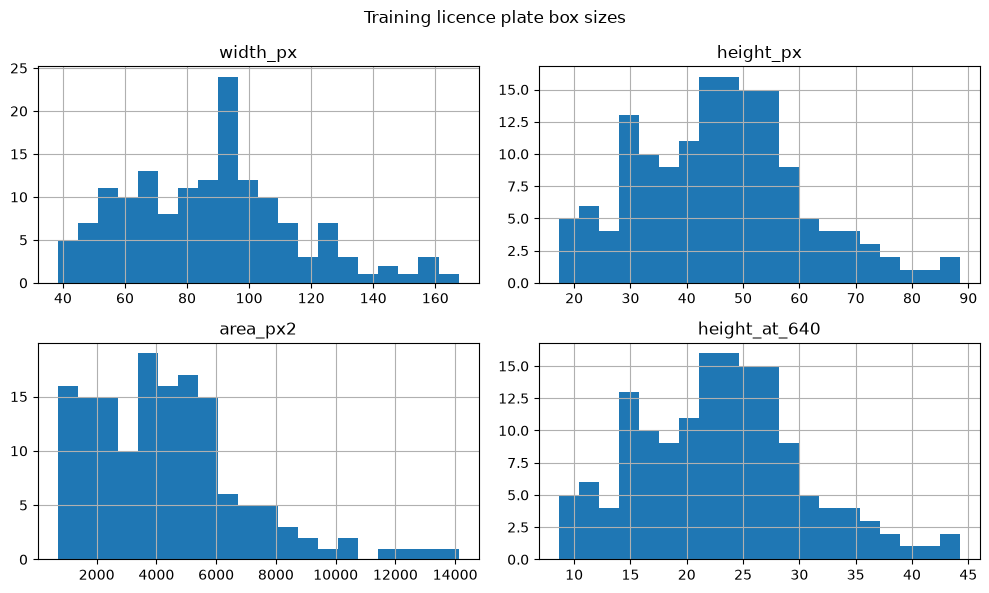

In [16]:
train_boxes = boxes.loc[boxes["split"] == "train"]
train_boxes[["width_px", "height_px", "area_px2", "height_at_640"]].hist(
    bins=20, figsize=(10, 6)
)
plt.suptitle("Training licence plate box sizes")
plt.tight_layout()
plt.show()

## 7. Visualize annotations

Keep image outputs local and clear them before sharing the notebook.

In [17]:
# From 02_POC.ipynb.
def yolo_to_xyxy(box, image_width, image_height):

    cx, cy, bw, bh = box

    cx *= image_width
    cy *= image_height

    bw *= image_width
    bh *= image_height

    x1 = cx - bw / 2
    y1 = cy - bh / 2

    x2 = cx + bw / 2
    y2 = cy + bh / 2

    return x1, y1, x2, y2

In [18]:
def show_annotations(split, image_id, title, highlight_line=None):
    image_path = dataset_dir / split / image_id
    rows = boxes.loc[(boxes["split"] == split) & (boxes["image_id"] == image_id)]

    fig, ax = plt.subplots(figsize=(13, 7))
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
        for row in rows.itertuples(index=False):
            box = (row.cx, row.cy, row.width_norm, row.height_norm)
            x1, y1, x2, y2 = yolo_to_xyxy(box, *image.size)
            color = "magenta" if row.line_number == highlight_line else "lime"
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   edgecolor=color, facecolor="none", linewidth=2))
    ax.set_title(f"{title} | {split} | {image_id}")
    ax.axis("off")
    plt.show()

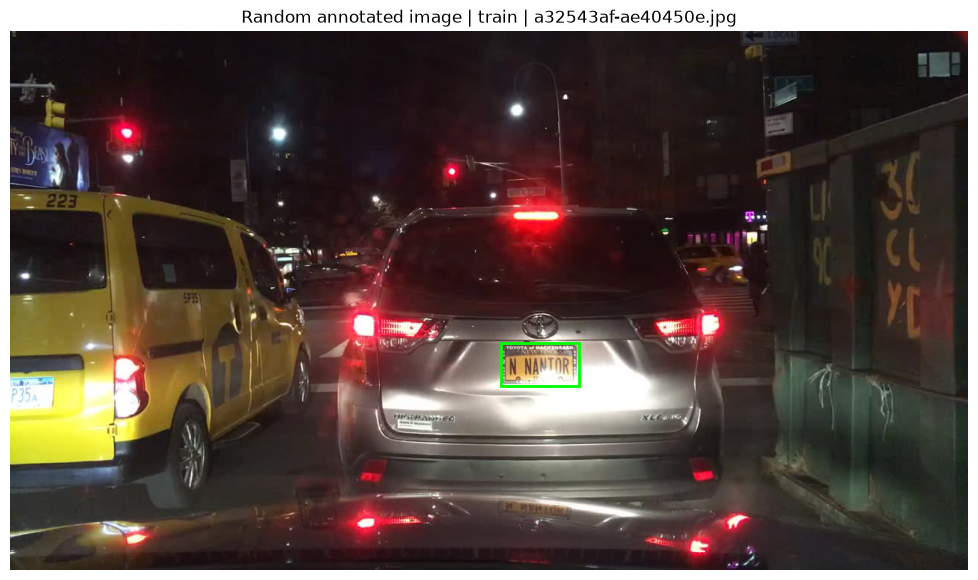

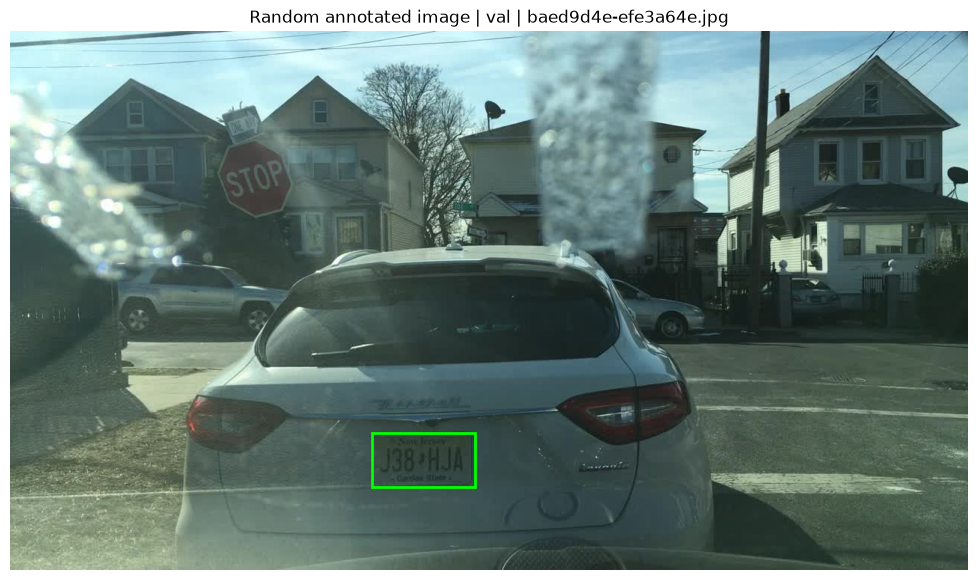

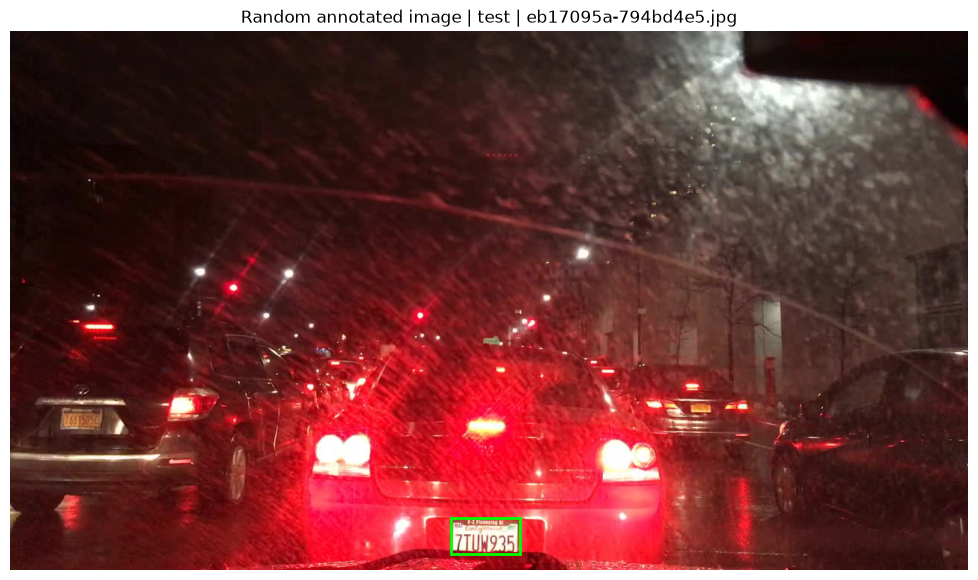

In [19]:
for split in expected_counts:
    positives = annotation_stats.loc[(annotation_stats["split"] == split) & annotation_stats["positive"]]
    example = positives.sample(1, random_state=seed).iloc[0]
    show_annotations(split, example["image_id"], "Random annotated image")

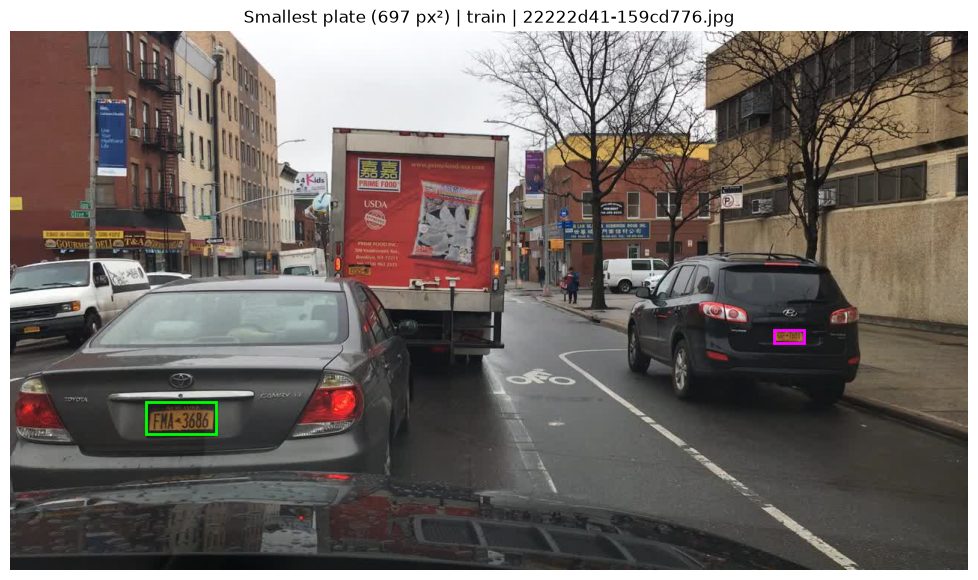

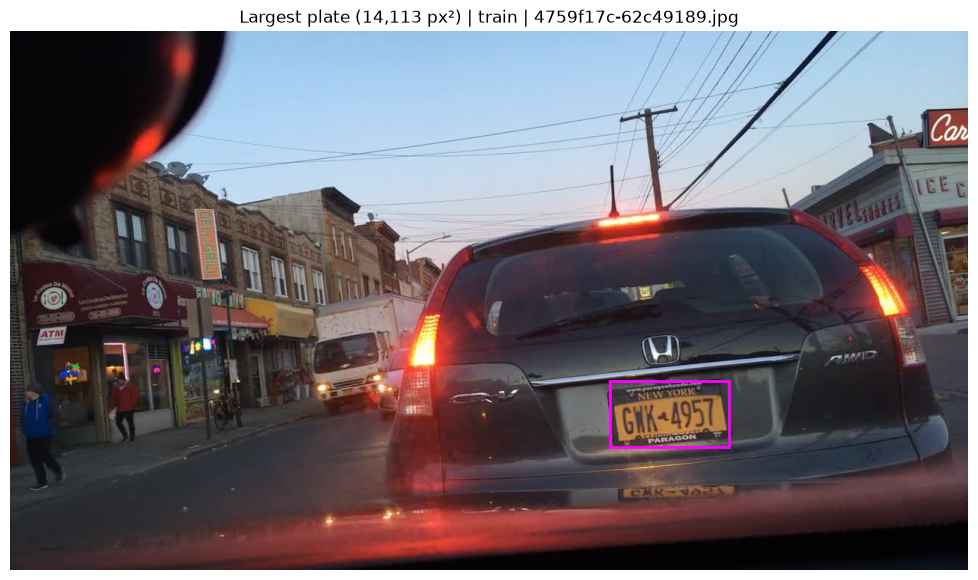

In [20]:
smallest = boxes.loc[boxes["area_px2"].idxmin()]
largest = boxes.loc[boxes["area_px2"].idxmax()]

for title, example in [("Smallest plate", smallest), ("Largest plate", largest)]:
    show_annotations(example["split"], example["image_id"],
                     f"{title} ({example['area_px2']:,.0f} px²)",
                     highlight_line=example["line_number"])

## 8. Final verification

In [21]:
assert problems.empty
assert data_yaml.read_text(encoding="utf-8") == yaml_text

for folder, names in generated_files.items():
    actual_names = {path.name for path in folder.iterdir() if path.is_file()}
    assert actual_names == names, f"File mismatch in {folder}"

for row in yolo_manifest.itertuples(index=False):
    image_path = yolo_dir / "images" / row.split / row.image_id
    assert sha256(image_path.read_bytes()).hexdigest() == row.image_hash, image_path

    label_path = yolo_dir / "labels" / row.split / f"{row.stem}.txt"
    expected_lines = [line.strip() for line in label_lines.get((row.split, row.stem), []) if line.strip()]
    assert label_path.read_text(encoding="utf-8").splitlines() == expected_lines, label_path

display(summary.reindex(expected_counts))
print(f"Dataset ready for training. Configuration: {data_yaml.relative_to(project_root)}")

,images,positive_images,negative_images,plates
split,,,,
train,158,142,16,151
val,17,15,2,15
test,15,13,2,16


Dataset ready for training. Configuration: data\dataset_v1\yolo_dataset\data.yaml


In [ ]:
### End of notebook 